# Tugas Praktikum
Multiple Linear Regression — Medical Cost Personal Dataset

**Tujuan:** memprediksi **biaya medis tahunan** (`charges`) seorang peserta asuransi berdasarkan beberapa variabel bebas.

**Deskripsi dataset** `insurance.csv` (1.338 baris):

| Kolom | Tipe | Keterangan |
|---|---|---|
| `age` | numerik | usia peserta |
| `sex` | kategorikal | jenis kelamin (female/male) |
| `bmi` | numerik | Body Mass Index |
| `children` | numerik | jumlah anak/tanggungan |
| `smoker` | kategorikal | status perokok (yes/no) |
| `region` | kategorikal | wilayah tempat tinggal (4 wilayah) |
| `charges` | numerik | **target** — biaya medis tahunan (dolar) |

### Langkah 1 - Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set(style='whitegrid')

### Langkah 2 - Memuat Data & Inspeksi Awal

In [2]:
df = pd.read_csv('insurance.csv')
print('Ukuran data:', df.shape)
df.head()

Ukuran data: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [4]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


Cek jumlah nilai unik pada kolom kategorikal dan pastikan tidak ada data kosong.

In [5]:
print('Missing values per kolom:')
print(df.isna().sum())
print()
for col in ['sex', 'smoker', 'region']:
    print(f'{col}: {df[col].unique()}')

Missing values per kolom:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

sex: <ArrowStringArray>
['female', 'male']
Length: 2, dtype: str
smoker: <ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str
region: <ArrowStringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str


### Langkah 3 - Analisis Data (EDA)
Lihat distribusi target `charges` dan hubungan fitur-fitur penting terhadap biaya medis.

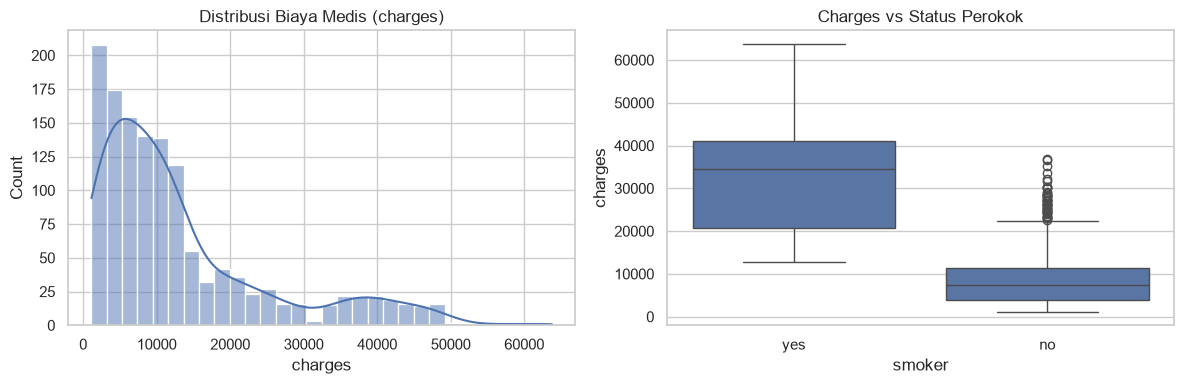

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['charges'], bins=30, kde=True, ax=axes[0])
axes[0].set_title('Distribusi Biaya Medis (charges)')
sns.boxplot(x='smoker', y='charges', data=df, ax=axes[1])
axes[1].set_title('Charges vs Status Perokok')
plt.tight_layout()
plt.show()

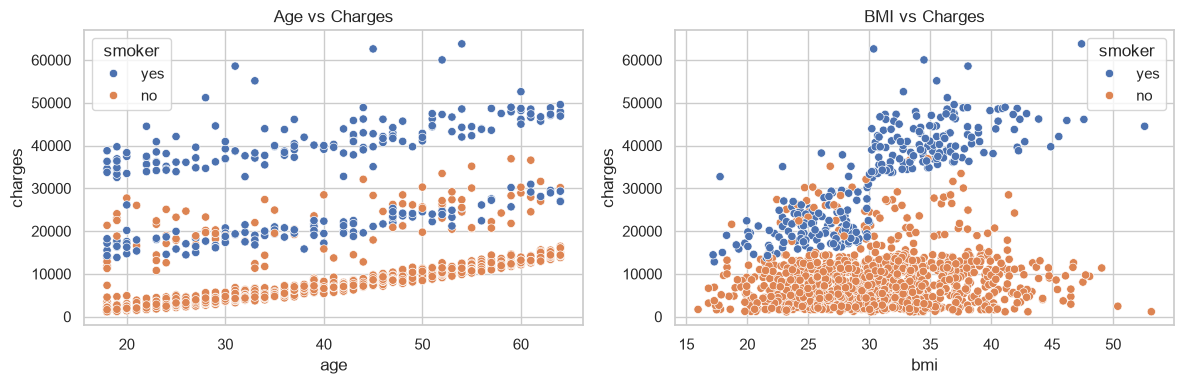

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(x='age', y='charges', hue='smoker', data=df, ax=axes[0])
axes[0].set_title('Age vs Charges')
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df, ax=axes[1])
axes[1].set_title('BMI vs Charges')
plt.tight_layout()
plt.show()

Heatmap korelasi antar variabel numerik. Terlihat `smoker` (setelah di-encode) dan `age` berkorelasi cukup kuat dengan `charges`.

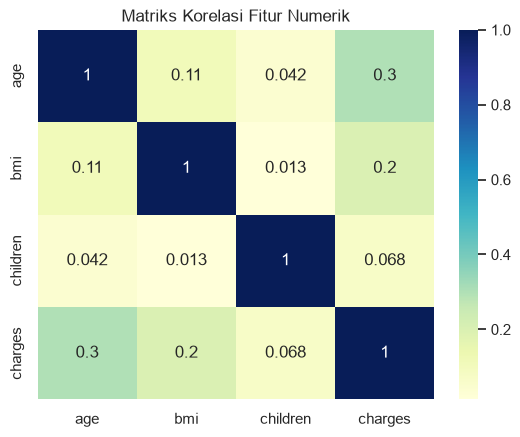

In [8]:
num_cols = ['age', 'bmi', 'children', 'charges']
sns.heatmap(df[num_cols].corr(), cmap='YlGnBu', annot=True)
plt.title('Matriks Korelasi Fitur Numerik')
plt.show()

### Langkah 4 - Pra-pengolahan Data
Kolom kategorikal (`sex`, `smoker`, `region`) diubah menjadi numerik dengan **one-hot encoding**. `drop_first=True` dipakai untuk menghindari *dummy variable trap* (kolinearitas sempurna).

In [9]:
df_enc = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)
df_enc = df_enc.astype({c: int for c in df_enc.columns if df_enc[c].dtype == bool})
print('Kolom setelah encoding:')
print(list(df_enc.columns))
df_enc.head()

Kolom setelah encoding:
['age', 'bmi', 'children', 'charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


### Langkah 5 - Menentukan Fitur (X) dan Target (y)
Semua kolom hasil encoding kecuali `charges` menjadi fitur.

In [10]:
X = df_enc.drop(columns=['charges'])
y = df_enc['charges']

print('Fitur (X):', list(X.columns))
print('Target (y): charges')

Fitur (X): ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']
Target (y): charges


### Langkah 6 - Pembagian Data Latih dan Uji
Proporsi **80% latih : 20% uji** dengan `random_state=42` agar hasil dapat direproduksi.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('Data latih:', X_train.shape, '| Data uji:', X_test.shape)

Data latih: (1070, 8) | Data uji: (268, 8)


### Langkah 7 - Feature Scaling
Standarisasi fitur dengan `StandardScaler`. Untuk regresi linier, scaling **tidak mengubah** R²/prediksi, tetapi membuat koefisien lebih mudah dibandingkan antar-fitur. Scaler di-*fit* hanya pada data latih untuk menghindari *data leakage*.

In [12]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

### Langkah 8 - Membuat & Melatih Model Multiple Linear Regression

In [13]:
model = LinearRegression()
model.fit(X_train_sc, y_train)

print('Intercept:', model.intercept_)
print('Jumlah koefisien:', len(model.coef_))

Intercept: 13346.089736364485
Jumlah koefisien: 8


### Langkah 9 - Prediksi dan Evaluasi Model
Hitung R², MSE, RMSE, dan MAE pada data uji.

In [14]:
y_pred = model.predict(X_test_sc)

r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)

print(f'R-squared : {r2:.4f}')
print(f'MSE       : {mse:.2f}')
print(f'RMSE      : {rmse:.2f}')
print(f'MAE       : {mae:.2f}')

R-squared : 0.7836
MSE       : 33596915.85
RMSE      : 5796.28
MAE       : 4181.19


### Langkah 10 - Interpretasi Koefisien Model
Koefisien menunjukkan pengaruh tiap fitur terhadap `charges` (karena fitur sudah distandarisasi, nilainya dapat dibandingkan relatif).

In [15]:
coef_df = pd.DataFrame({
    'Fitur': X.columns,
    'Koefisien': model.coef_,
}).sort_values('Koefisien', key=abs, ascending=False)
coef_df

,Fitur,Koefisien
4,smoker_yes,9558.481409
0,age,3614.975415
1,bmi,2036.228123
2,children,516.890247
7,region_southwest,-349.110678
6,region_southeast,-290.157047
5,region_northwest,-158.140981
3,sex_male,-9.293101


### Langkah 11 - Visualisasi Hasil
Scatter *actual vs predicted* (idealnya mengikuti garis diagonal) dan plot residual.

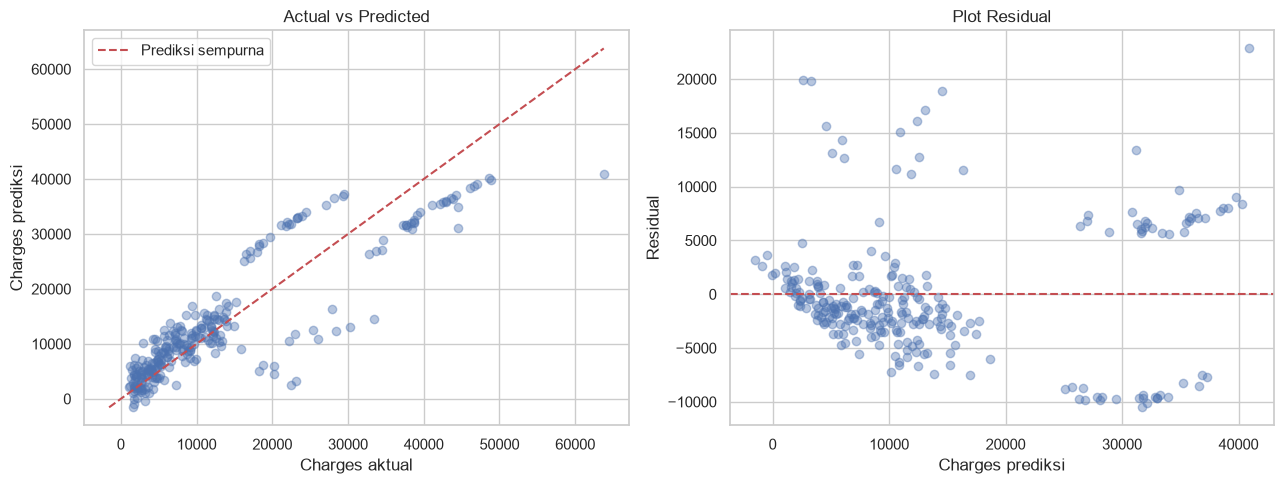

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, y_pred, alpha=0.4)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, 'r--', label='Prediksi sempurna')
axes[0].set_xlabel('Charges aktual')
axes[0].set_ylabel('Charges prediksi')
axes[0].set_title('Actual vs Predicted')
axes[0].legend()

residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, alpha=0.4)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_xlabel('Charges prediksi')
axes[1].set_ylabel('Residual')
axes[1].set_title('Plot Residual')

plt.tight_layout()
plt.show()

### Langkah 12 - Perbandingan dengan SVR (opsional)
Modul juga menyebut SVR. Sebagai pembanding, kita latih SVR (kernel RBF) pada data yang sama. Karena SVR berbasis jarak, fitur **dan target** perlu distandarisasi.

In [17]:
from sklearn.svm import SVR

sc_y = StandardScaler()
y_train_sc = sc_y.fit_transform(y_train.values.reshape(-1, 1)).ravel()
y_test_sc = sc_y.transform(y_test.values.reshape(-1, 1)).ravel()

svr = SVR(kernel='rbf')
svr.fit(X_train_sc, y_train_sc)
y_pred_svr_sc = svr.predict(X_test_sc)
y_pred_svr = sc_y.inverse_transform(y_pred_svr_sc.reshape(-1, 1)).ravel()

print(f'SVR  R-squared: {r2_score(y_test, y_pred_svr):.4f}')
print(f'SVR  RMSE     : {np.sqrt(mean_squared_error(y_test, y_pred_svr)):.2f}')
print(f'SVR  MAE      : {mean_absolute_error(y_test, y_pred_svr):.2f}')

print()
print(f'Linear Regression R-squared: {r2:.4f}')
print(f'Linear Regression RMSE     : {rmse:.2f}')
print(f'Linear Regression MAE      : {mae:.2f}')

SVR  R-squared: 0.8623
SVR  RMSE     : 4623.88
SVR  MAE      : 2462.45

Linear Regression R-squared: 0.7836
Linear Regression RMSE     : 5796.28
Linear Regression MAE      : 4181.19


### Analisis dan Kesimpulan

**Hasil:**

* Model **Multiple Linear Regression** memberi **R² ≈ 0,78** pada data uji — model mampu menjelaskan sekitar 78% variasi biaya medis.
* **RMSE ≈ $5.796** dan **MAE ≈ $4.181**, artinya rata-rata kesalahan prediksi sekitar $4.200 per peserta.
* Fitur paling berpengaruh adalah **status perokok (`smoker_yes`)**, diikuti **usia (`age`)** dan **BMI (`bmi`)**. Ini konsisten dengan temuan EDA: perokok punya `charges` jauh lebih tinggi.
* Koefisien `children` dan wilayah relatif kecil pengaruhnya.

**Catatan penting:**

1. `region` dan `sex` di-*one-hot encode* (`drop_first=True`) agar tidak terjadi *dummy variable trap*.
2. `StandardScaler` di-*fit* hanya pada data latih, lalu dipakai untuk transform data uji (mencegah *data leakage*).
3. Untuk regresi linier, scaling tidak mengubah R², tetapi membuat koefisien sebanding.
4. **SVR (RBF)** justru memberi hasil **lebih baik** (R² ≈ 0,86, RMSE ≈ $4.624, MAE ≈ $2.462). Ini menunjukkan adanya pola **non-linier** — terutama interaksi **BMI × status perokok**: kenaikan BMI menaikkan biaya jauh lebih tajam pada perokok, dan model linier tidak menangkap interaksi tersebut.

**Kesimpulan:** biaya medis personal dapat diprediksi dengan baik, dengan **status merokok sebagai faktor dominan**. Regresi linier berganda mudah diinterpretasikan (R² ≈ 0,78), sedangkan SVR lebih akurat untuk menangkap pola non-linier (R² ≈ 0,86).